# Exploratory Data Analysis: ToxValDB_v9.7.0_Cleaned

This notebook provides a comprehensive analysis of the ToxValDB dataset, focusing on:
- **Data Overview**: Types, missing values (standard and custom placeholders), and general structure.
- **Univariate Analysis**: Distributions of numerical and categorical variables, including outlier detection.
- **Extreme outlier inspection**: Detailed view of the most extreme values for key numerical columns.
- **Biological Outlier Detection**: Validating study durations against species-specific life expectancies.
- **Bivariate Analysis**: Categorical vs Numerical relationships.

---

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

# Ensure all columns are shown when displaying DataFrames
pd.set_option('display.max_columns', None)

## 1. Load Data
We load the TSV file and take a first look at the structure.

In [16]:
file_path = '../02_processed_data/ToxValDB_v9.7.0_Cleaned_00.tsv'
df = pd.read_csv(file_path, sep='\t')

print(f"Original shape of dataset: {df.shape}")
df.head()

Original shape of dataset: (116059, 34)


,DTXSID,CASRN,NAME,SOURCE,SUB_SOURCE,TOXVAL_TYPE,TOXVAL_SUBTYPE,TOXVAL_TYPE_SUPERCATEGORY,QUALIFIER,TOXVAL_NUMERIC,TOXVAL_UNITS,RISK_ASSESSMENT_CLASS,STUDY_TYPE,STUDY_DURATION_CLASS,STUDY_DURATION_VALUE,STUDY_DURATION_UNITS,SPECIES_COMMON,STRAIN,LATIN_NAME,SPECIES_SUPERCATEGORY,SEX,GENERATION,LIFESTAGE,EXPOSURE_ROUTE,EXPOSURE_METHOD,EXPOSURE_FORM,MEDIA,TOXICOLOGICAL_EFFECT,TOXICOLOGICAL_EFFECT_CATEGORY,EXPERIMENTAL_RECORD,STUDY_GROUP,YEAR,ORIGINAL_YEAR,MATRIX_GUIDELINE
0,DTXSID3021774,83-32-9,Acenaphthene,ATSDR MRLs,-,MRL,intermediate,Toxicity Value,=,0.600000,mg/kg-day,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,oral,-,-,-,hepatic mice,-,not experimental,ATSDR MRLs:15446843:-:--,1995,1995,NaN
1,DTXSID8021482,67-64-1,Acetone,ATSDR MRLs,-,MRL,acute,Toxicity Value,=,19.003800,mg/m3,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,inhalation,-,-,-,neurological,-,not experimental,ATSDR MRLs:15446844:-:--,2022,2022,NaN
2,DTXSID8021482,67-64-1,Acetone,ATSDR MRLs,-,MRL,intermediate,Toxicity Value,=,0.600000,mg/kg-day,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,oral,-,-,-,hematological rats,-,not experimental,ATSDR MRLs:15446845:-:--,2022,2022,NaN
3,DTXSID5020023,107-02-8,Acrolein,ATSDR MRLs,-,MRL,acute,Toxicity Value,=,0.006879,mg/m3,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,inhalation,-,-,-,respiratory,-,not experimental,ATSDR MRLs_dup_-_15446846_15446847:-:--,2007,2007,NaN
4,DTXSID5020023,107-02-8,Acrolein,ATSDR MRLs,-,MRL,intermediate,Toxicity Value,=,0.000092,mg/m3,Non-cancer,Toxicity Value,-,-999.0,-,Human,-,Homo sapiens,Mammals,-,-,-,inhalation,-,-,-,respiratory rats,-,not experimental,ATSDR MRLs_dup_-_15446846_15446847:-:--,2007,2007,NaN


In [17]:
df.columns

Index(['DTXSID', 'CASRN', 'NAME', 'SOURCE', 'SUB_SOURCE', 'TOXVAL_TYPE',
       'TOXVAL_SUBTYPE', 'TOXVAL_TYPE_SUPERCATEGORY', 'QUALIFIER',
       'TOXVAL_NUMERIC', 'TOXVAL_UNITS', 'RISK_ASSESSMENT_CLASS', 'STUDY_TYPE',
       'STUDY_DURATION_CLASS', 'STUDY_DURATION_VALUE', 'STUDY_DURATION_UNITS',
       'SPECIES_COMMON', 'STRAIN', 'LATIN_NAME', 'SPECIES_SUPERCATEGORY',
       'SEX', 'GENERATION', 'LIFESTAGE', 'EXPOSURE_ROUTE', 'EXPOSURE_METHOD',
       'EXPOSURE_FORM', 'MEDIA', 'TOXICOLOGICAL_EFFECT',
       'TOXICOLOGICAL_EFFECT_CATEGORY', 'EXPERIMENTAL_RECORD', 'STUDY_GROUP',
       'YEAR', 'ORIGINAL_YEAR', 'MATRIX_GUIDELINE'],
      dtype='object')

## 2. Advanced Missing Value Analysis
In many datasets, missing values are represented by placeholders like `'-'`, `'None'`, or numerical values like `-999.0`.

In [18]:
# Define potential placeholders for missing data
custom_na_values = ['-', 'None', 'NONE', '.', 'N/A', 'null', 'NULL', -999, -999.0, '-999', '-999.0']

missing_summary = {}

for col in df.columns:
    # Current NaNs
    nan_count = df[col].isna().sum()
    
    # Custom placeholders
    placeholder_count = df[col].isin(custom_na_values).sum()
    
    total_missing = nan_count + placeholder_count
    missing_summary[col] = {
        'Actual NaNs': nan_count,
        'Custom Placeholders': placeholder_count,
        'Total Missing': total_missing,
        '% Missing': round(total_missing / len(df) * 100, 2)
    }

missing_df = pd.DataFrame(missing_summary).T
display(missing_df.sort_values('% Missing', ascending=False))

print("Converting custom placeholders to np.nan for further analysis...")
df = df.replace(custom_na_values, np.nan)

,Actual NaNs,Custom Placeholders,Total Missing,% Missing
RISK_ASSESSMENT_CLASS,0.0,113458.0,113458.0,97.76
LIFESTAGE,0.0,112168.0,112168.0,96.65
GENERATION,0.0,107053.0,107053.0,92.24
TOXVAL_SUBTYPE,0.0,105221.0,105221.0,90.66
EXPOSURE_FORM,0.0,98097.0,98097.0,84.52
MEDIA,0.0,83783.0,83783.0,72.19
ORIGINAL_YEAR,0.0,46673.0,46673.0,40.21
YEAR,0.0,46663.0,46663.0,40.21
STUDY_DURATION_VALUE,0.0,31643.0,31643.0,27.26
STUDY_DURATION_UNITS,0.0,31643.0,31643.0,27.26


Converting custom placeholders to np.nan for further analysis...


### 2.2 Re-check Missing Values and Data Types
After replacement, we redefine numerical and categorical columns as some placeholders (like `-`) might have forced numerical columns to be objects.

,Dtype,Unique Values,Missing Values,Percentage Missing
DTXSID,object,9142,0,0.00
CASRN,object,9141,6,0.01
NAME,object,9263,6,0.01
SOURCE,object,38,0,0.00
SUB_SOURCE,object,29,20231,17.43
TOXVAL_TYPE,object,138,0,0.00
TOXVAL_SUBTYPE,object,50,105221,90.66
TOXVAL_TYPE_SUPERCATEGORY,object,5,0,0.00
QUALIFIER,object,6,0,0.00
TOXVAL_NUMERIC,float64,6364,0,0.00


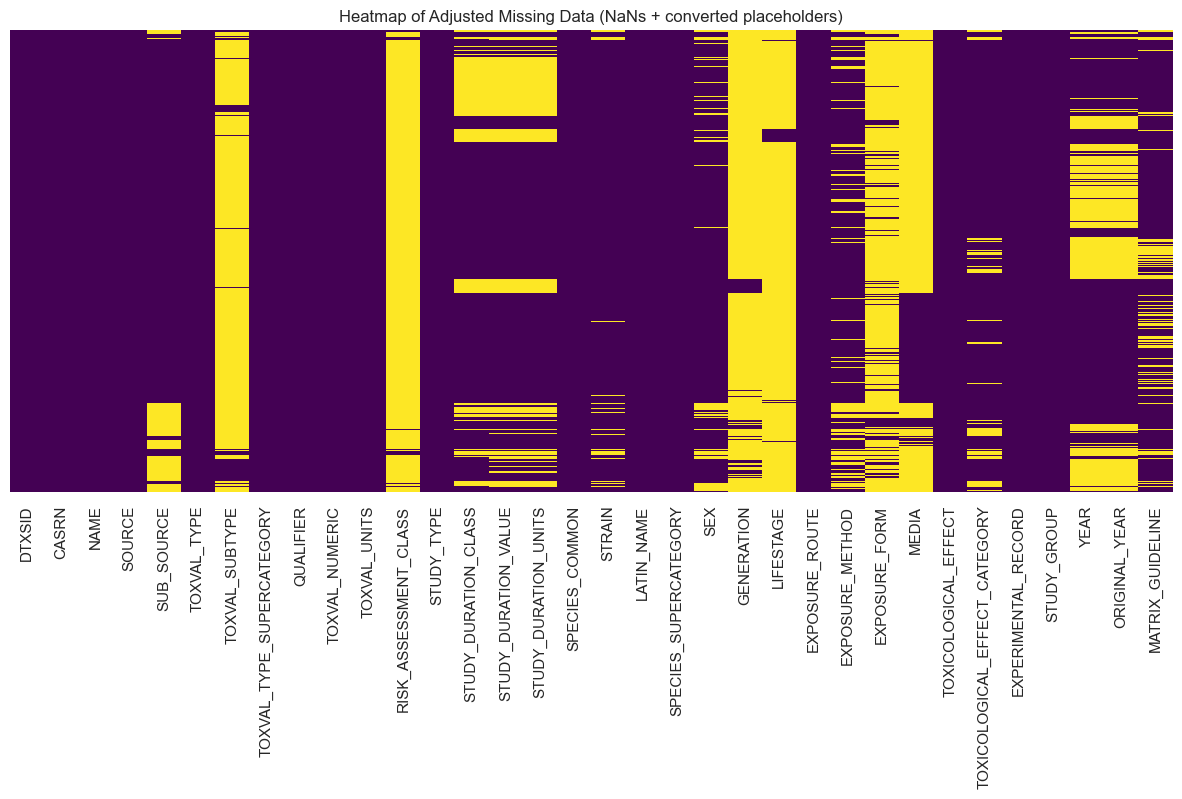

In [19]:
# Attempt to infer better types after removing placeholders
df = df.apply(pd.to_numeric, errors='ignore')

info_df = pd.DataFrame({
    'Dtype': df.dtypes,
    'Unique Values': df.nunique(),
    'Missing Values': df.isnull().sum(),
    'Percentage Missing': (df.isnull().sum() / len(df) * 100).round(2)
})
display(info_df)

# Visualize adjusted missing data
plt.figure(figsize=(15, 6))
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.title("Heatmap of Adjusted Missing Data (NaNs + converted placeholders)")
plt.show()

## 3. Univariate Analysis
We analyze columns based on their updated data type.

In [20]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Numerical columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['TOXVAL_NUMERIC', 'STUDY_DURATION_VALUE']
Categorical columns: ['DTXSID', 'CASRN', 'NAME', 'SOURCE', 'SUB_SOURCE', 'TOXVAL_TYPE', 'TOXVAL_SUBTYPE', 'TOXVAL_TYPE_SUPERCATEGORY', 'QUALIFIER', 'TOXVAL_UNITS', 'RISK_ASSESSMENT_CLASS', 'STUDY_TYPE', 'STUDY_DURATION_CLASS', 'STUDY_DURATION_UNITS', 'SPECIES_COMMON', 'STRAIN', 'LATIN_NAME', 'SPECIES_SUPERCATEGORY', 'SEX', 'GENERATION', 'LIFESTAGE', 'EXPOSURE_ROUTE', 'EXPOSURE_METHOD', 'EXPOSURE_FORM', 'MEDIA', 'TOXICOLOGICAL_EFFECT', 'TOXICOLOGICAL_EFFECT_CATEGORY', 'EXPERIMENTAL_RECORD', 'STUDY_GROUP', 'YEAR', 'ORIGINAL_YEAR', 'MATRIX_GUIDELINE']


## 5. Biological Outlier Detection: Study Duration vs Life Expectancy
Certain study durations might exceed the biological lifespan of the species involved (e.g., a Rat with a study of 80 years).

In [21]:
# Mapping of Species to estimated Max Lifespan in YEARS
lifespan_map = {
    'Rat': 4,
    'Mouse': 4,
    'Rabbit': 12,
    'European Rabbit': 12,
    'Human': 120,
    'Dog': 18,
    'Guinea Pig': 8,
    'Monkey': 40,
    'Rhesus Macaque': 40,
    'Cat': 25,
    'Hamster': 4,
    'Pig': 20,
    'Mink': 10,
    'American Mink': 10,
    'Gerbil': 5,
    'Japanese Quail': 3,
    'Chicken': 8,
    'Sheep': 12,
    'Zebra Danio': 5,
    'Northern Bobwhite Quail': 8,
    'Cow Family': 20
}

# Print unique species to ensure none are missing
print("### Unique Species in Dataset:")
print(sorted(df['SPECIES_COMMON'].dropna().unique()))
print("\n")

# Conversion factor to standardize EVERYTHING to years
unit_to_years = {
    'years': 1.0,
    'year': 1.0,
    'months': 1/12,
    'month': 1/12,
    'weeks': 1/52.17,
    'week': 1/52.17,
    'days': 1/365.25,
    'day': 1/365.25,
    'hours': 1/(24*365.25),
    'minutes': 1/(60*24*365.25),
    'generation': 1.0 # conservatively assume 1 generation <= max lifespan
}

if 'STUDY_DURATION_VALUE' in df.columns and 'STUDY_DURATION_UNITS' in df.columns:
    # Create standardized column for comparison
    df['STUDY_DURATION_YEARS'] = df.apply(
        lambda row: row['STUDY_DURATION_VALUE'] * unit_to_years.get(str(row['STUDY_DURATION_UNITS']).lower(), 0) 
        if pd.notnull(row['STUDY_DURATION_VALUE']) else np.nan, 
        axis=1
    )
    
    # Mark outliers
    def is_bio_outlier(row):
        species = row['SPECIES_COMMON']
        dur_years = row['STUDY_DURATION_YEARS']
        if pd.isnull(species) or pd.isnull(dur_years): return False
        
        # Approximate check for multi-species strings (take max if multiple)
        if ',' in str(species):
            parts = [p.strip() for p in str(species).split(',')]
            limit = max([lifespan_map.get(p, 100) for p in parts])
        else:
            limit = lifespan_map.get(species, 100) # Default to 100 for unknown species
            
        return dur_years > limit

    bio_outliers = df[df.apply(is_bio_outlier, axis=1)]
    
    print(f"Detected {len(bio_outliers)} biological outliers for STUDY_DURATION (Duration > Species Lifespan).")
    if len(bio_outliers) > 0:
        # Show all columns for the detected outliers as requested
        display(bio_outliers.head(10))
    
    # Let's show the ones for the top species
    print("--- Species with Biological Outliers ---")
    print(bio_outliers['SPECIES_COMMON'].value_counts())


### Unique Species in Dataset:
['American Mink', "Bird's-foot Trefoils", 'Cat', 'Chicken', 'Cow Family', 'Dog', 'Eel Order', 'European Rabbit', 'Gerbil', 'Guinea Pig', 'Guinea Pig, Rat', 'Hamster', 'House Mouse', 'Human', 'Japanese Quail', 'Mink', 'Monkey', 'Mouse', 'Mouse, Rat', 'Northern Bobwhite Quail', 'Pig', 'Primate', 'Quail', 'Rabbit', 'Rat', 'Rhesus Macaque', 'Sheep', 'Western European House Mouse', 'Zebra Danio', 'cat, guinea pig', 'rodent']


Detected 5 biological outliers for STUDY_DURATION (Duration > Species Lifespan).


,DTXSID,CASRN,NAME,SOURCE,SUB_SOURCE,TOXVAL_TYPE,TOXVAL_SUBTYPE,TOXVAL_TYPE_SUPERCATEGORY,QUALIFIER,TOXVAL_NUMERIC,TOXVAL_UNITS,RISK_ASSESSMENT_CLASS,STUDY_TYPE,STUDY_DURATION_CLASS,STUDY_DURATION_VALUE,STUDY_DURATION_UNITS,SPECIES_COMMON,STRAIN,LATIN_NAME,SPECIES_SUPERCATEGORY,SEX,GENERATION,LIFESTAGE,EXPOSURE_ROUTE,EXPOSURE_METHOD,EXPOSURE_FORM,MEDIA,TOXICOLOGICAL_EFFECT,TOXICOLOGICAL_EFFECT_CATEGORY,EXPERIMENTAL_RECORD,STUDY_GROUP,YEAR,ORIGINAL_YEAR,MATRIX_GUIDELINE,STUDY_DURATION_YEARS
2251,DTXSID3020203,106-99-0,"1,3-Butadiene",Cal OEHHA REL derivations,NaN,BMC (05),NaN,Dose Response Summary Value,=,3.09731,mg/m3,NaN,chronic,chronic,103.0,months,Mouse,B6C3F1,Mus musculus,Mammals,M/F,NaN,NaN,inhalation,discontinuous inhalation,NaN,NaN,increased incidence of ovarian atrophy,NaN,experimental,Cal OEHHA REL derivations:15952007:M/F:--,2000,2000,OECD 452,8.583333
36281,DTXSID901231803,96624-41-8,"(trans,trans)-4-Ethyl-4\'-propyl-1,1\'-bicyclo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOAEL,NaN,Dose Response Summary Value,=,300.00000,mg/kg-day,NaN,chronic,chronic,31526.0,days,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,NaN,NaN,oral,gavage,NaN,NaN,organ weight and organ / body weight ratios,organ weight,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,2001,2001,OECD 452,86.313484
36282,DTXSID901231803,96624-41-8,"(trans,trans)-4-Ethyl-4\'-propyl-1,1\'-bicyclo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOEL,NaN,Dose Response Summary Value,=,30.00000,mg/kg-day,NaN,chronic,chronic,31526.0,days,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,NaN,NaN,oral,gavage,NaN,NaN,organ weight and organ / body weight ratios,organ weight,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,2001,2001,OECD 452,86.313484
41810,DTXSID901231803,96624-41-8,"(trans,trans)-4-Ethyl-4\'-propyl-1,1\'-bicyclo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOAEL,NaN,Dose Response Summary Value,=,300.00000,mg/kg-day,NaN,chronic,chronic,31526.0,days,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,NaN,NaN,oral,gavage,NaN,NaN,organ weight and organ / body weight ratios,organ weight,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,2009,2009,OECD 452,86.313484
41811,DTXSID901231803,96624-41-8,"(trans,trans)-4-Ethyl-4\'-propyl-1,1\'-bicyclo...",ECHA IUCLID,Repeated Dose Toxicity Oral,NOEL,NaN,Dose Response Summary Value,=,30.00000,mg/kg-day,NaN,chronic,chronic,31526.0,days,Rat,Not Specified,Rattus norvegicus,Mammals,M/F,NaN,NaN,oral,gavage,NaN,NaN,organ weight and organ / body weight ratios,organ weight,experimental,ECHA IUCLID_dup_Repeated Dose Toxicity Oral_15...,2009,2009,OECD 452,86.313484


--- Species with Biological Outliers ---
SPECIES_COMMON
Rat      4
Mouse    1
Name: count, dtype: int64


## 6. Categorical Columns Analysis

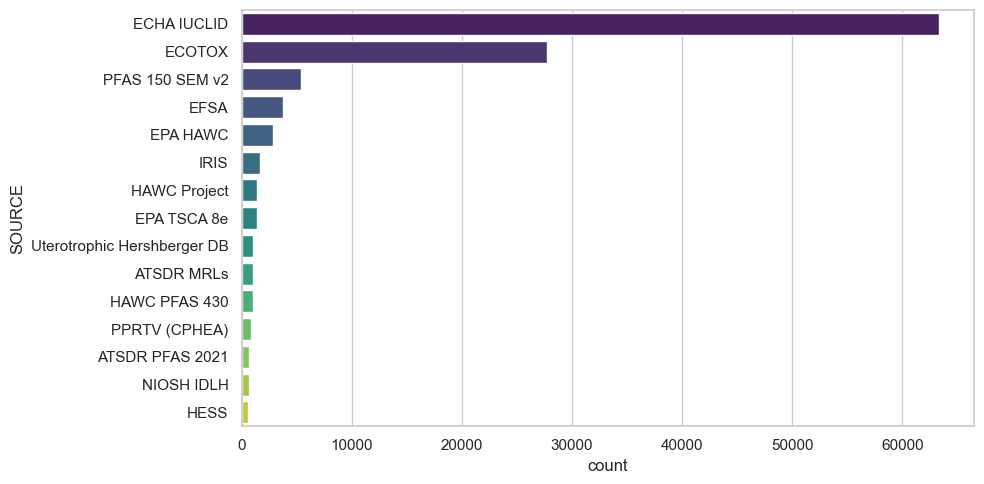

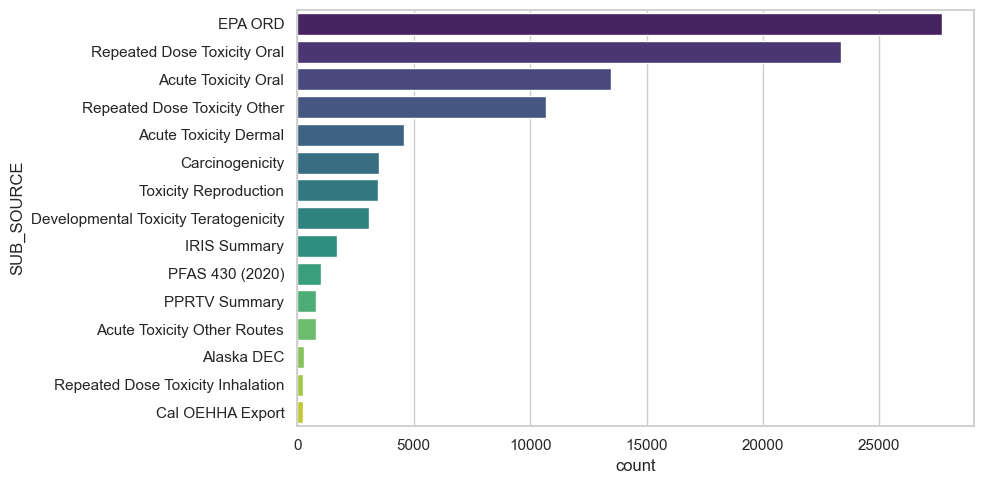

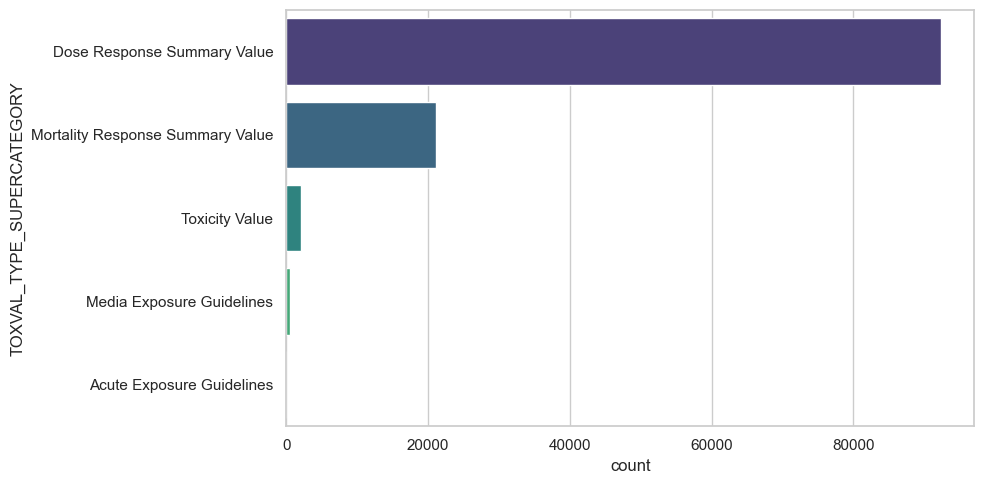

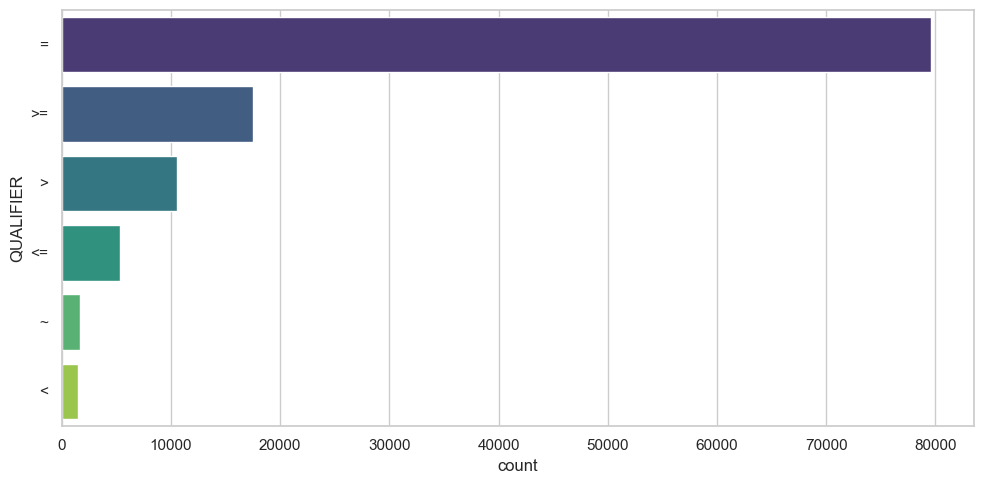

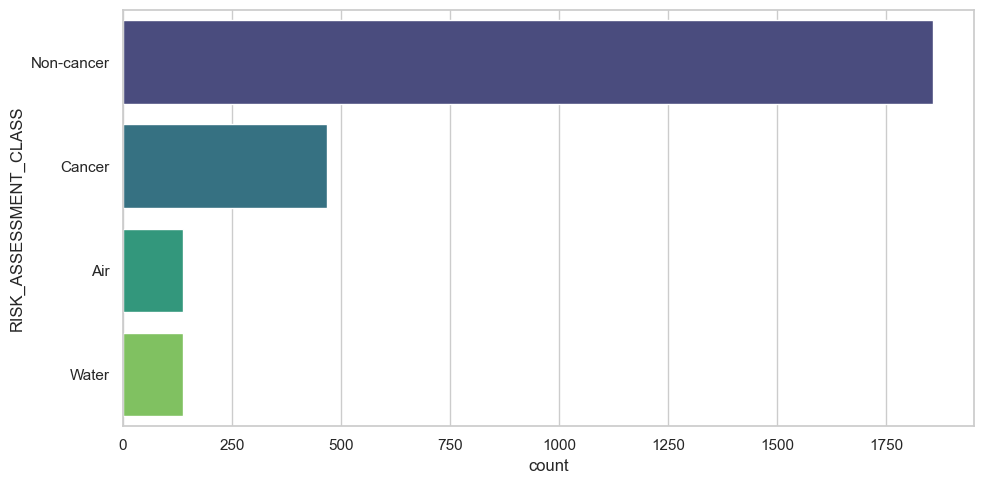

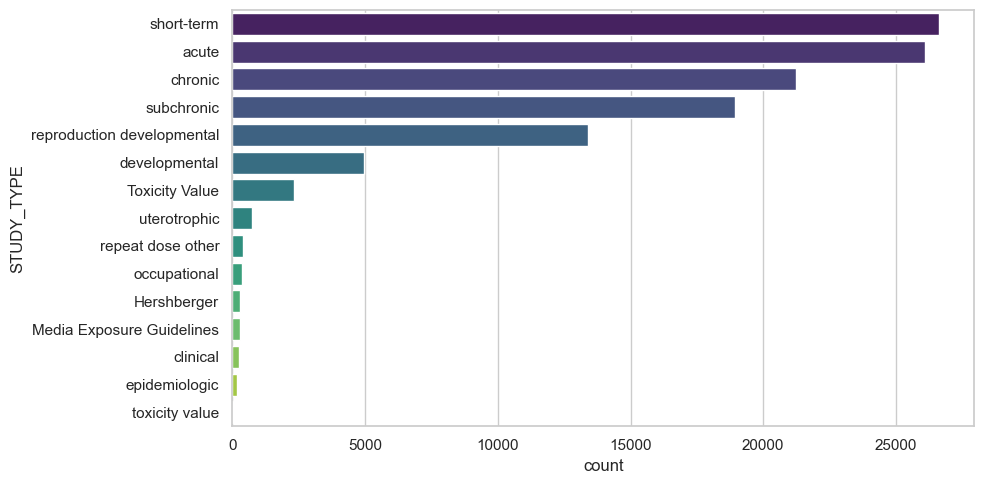

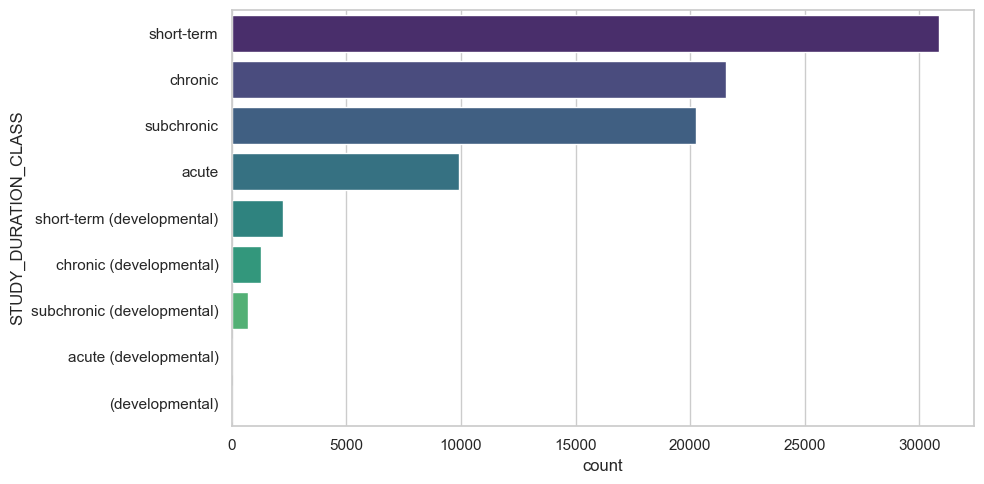

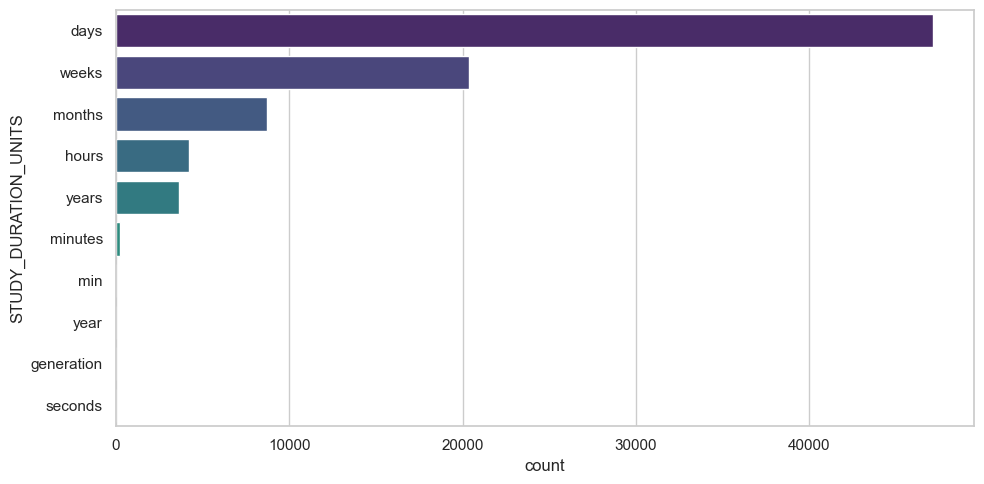

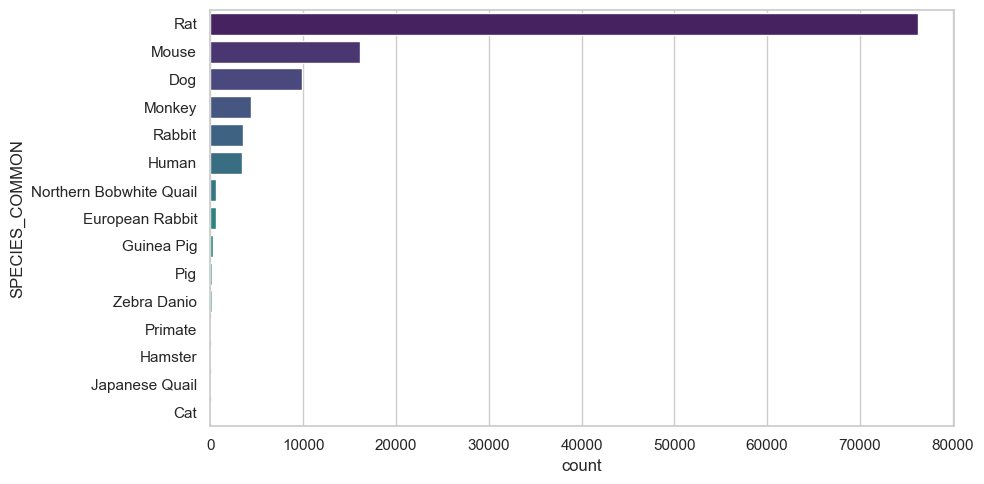

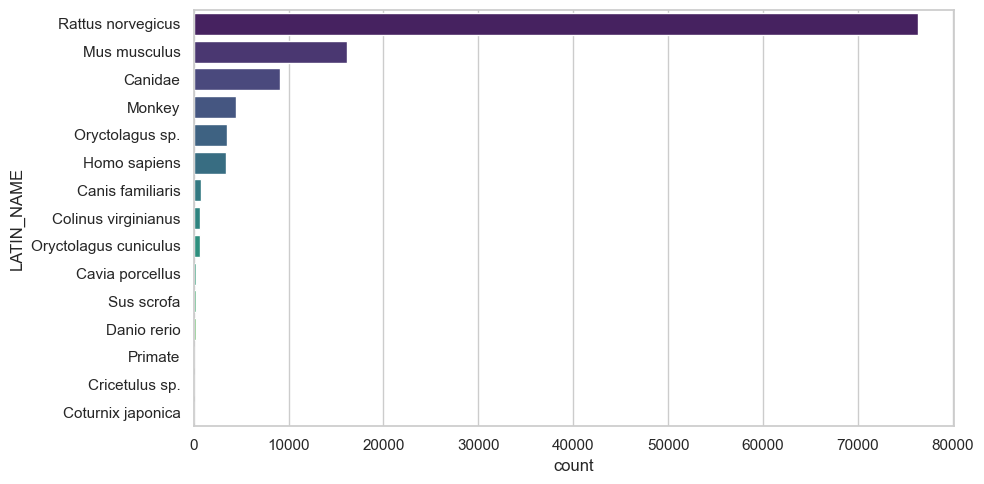

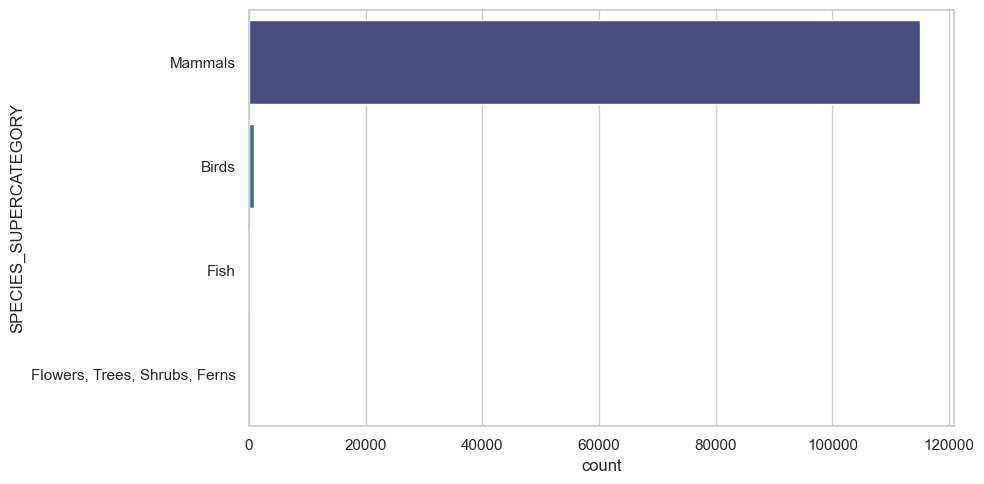

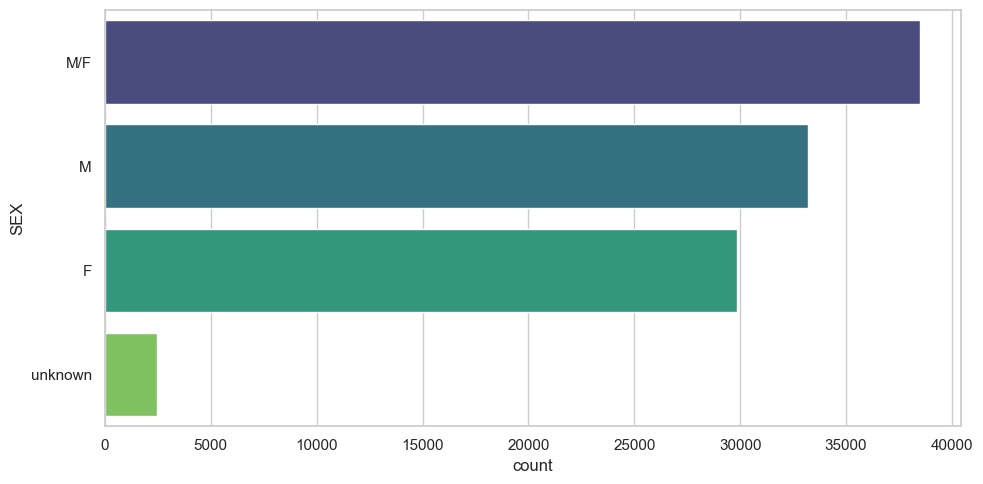

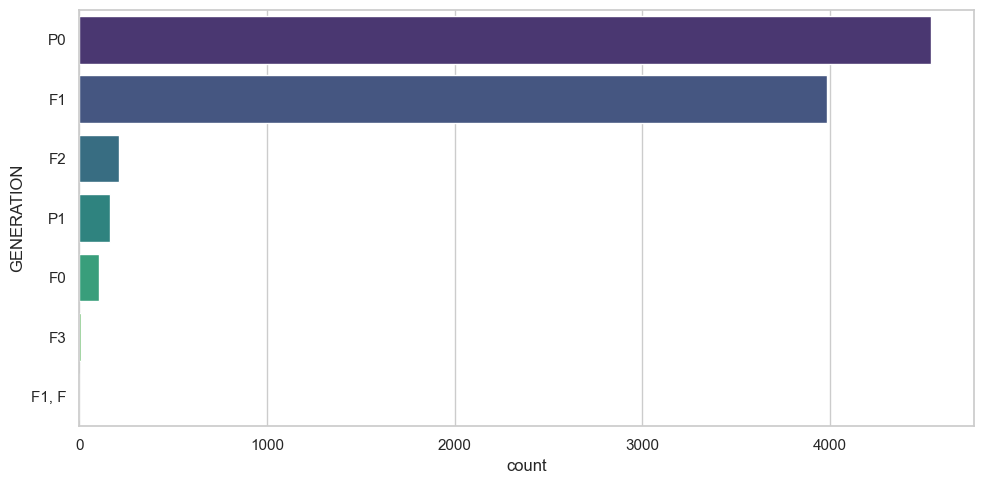

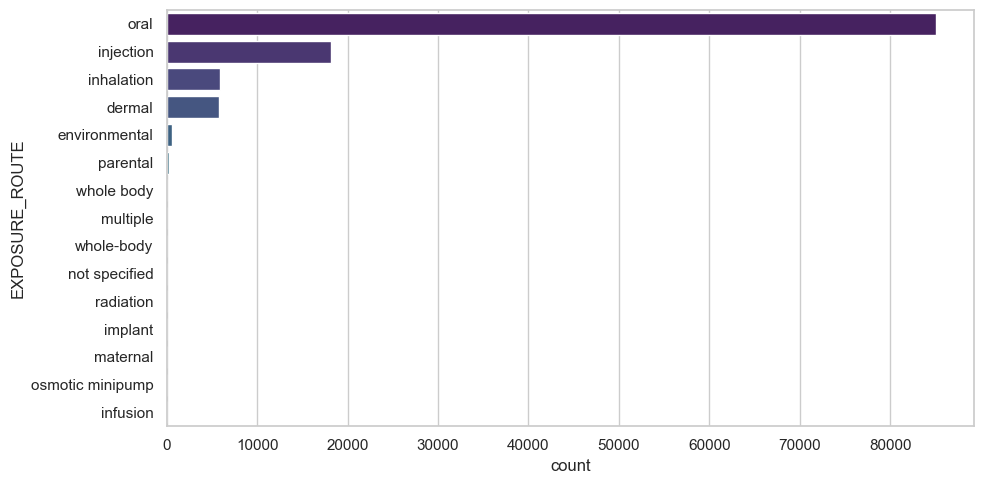

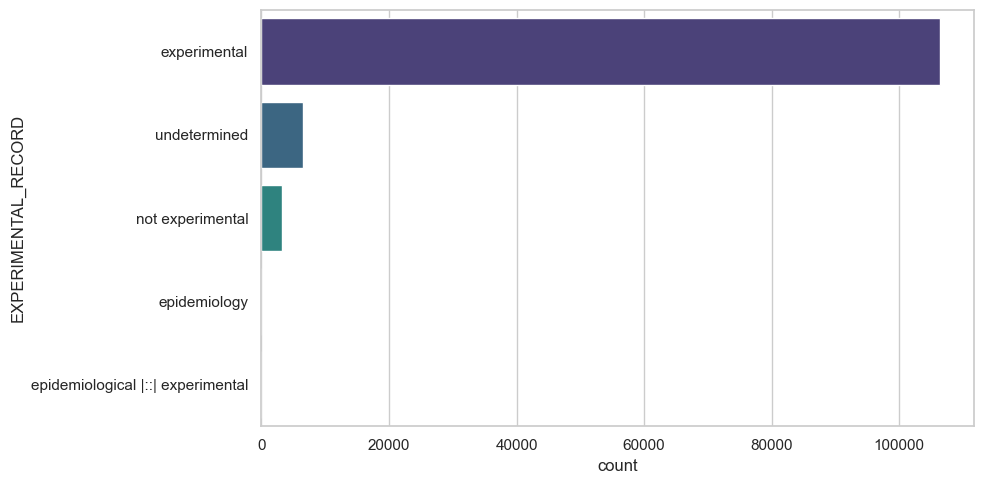

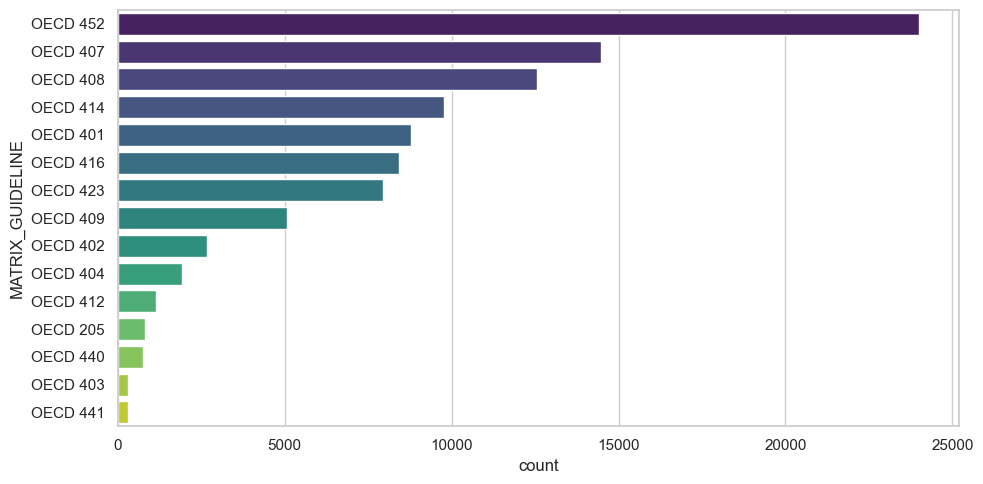

In [22]:
# Filter for columns with reasonable number of categories < 50
cat_to_plot = [c for c in categorical_cols if df[c].nunique() < 50]

for col in cat_to_plot:
    if df[col].nunique() == 0: continue
    
    plt.figure(figsize=(10, 5))
    order = df[col].value_counts().iloc[:15].index
    sns.countplot(data=df, y=col, order=order, palette="viridis")
    # plt.title(f"Top Categories for {col}")
    plt.tight_layout()
    plt.show()

## 7. Bivariate Analysis: Categorical vs Numerical
We examine how numerical values are distributed across different units and exposure routes.

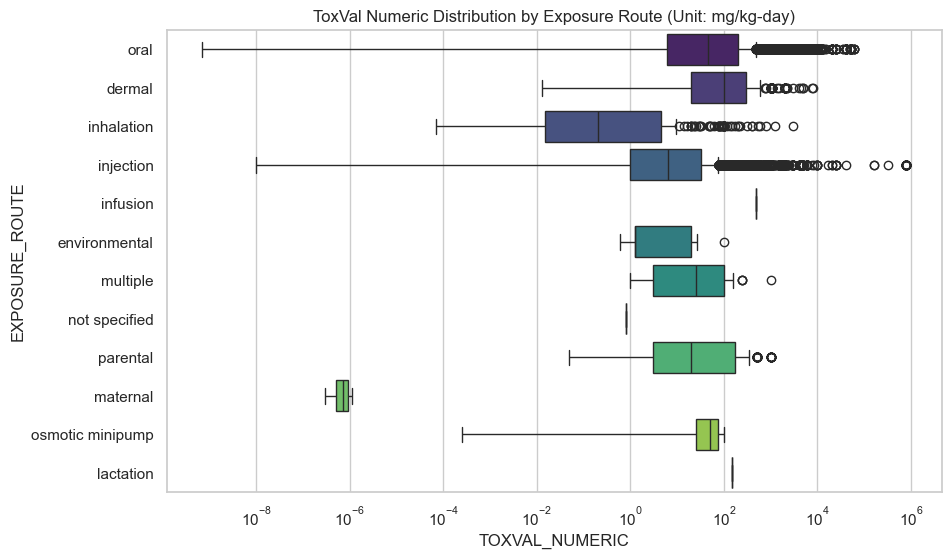

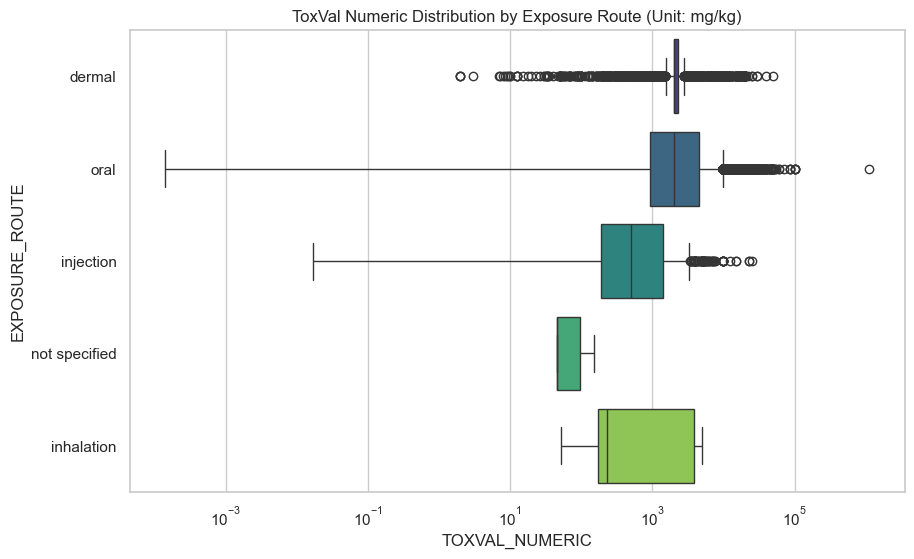

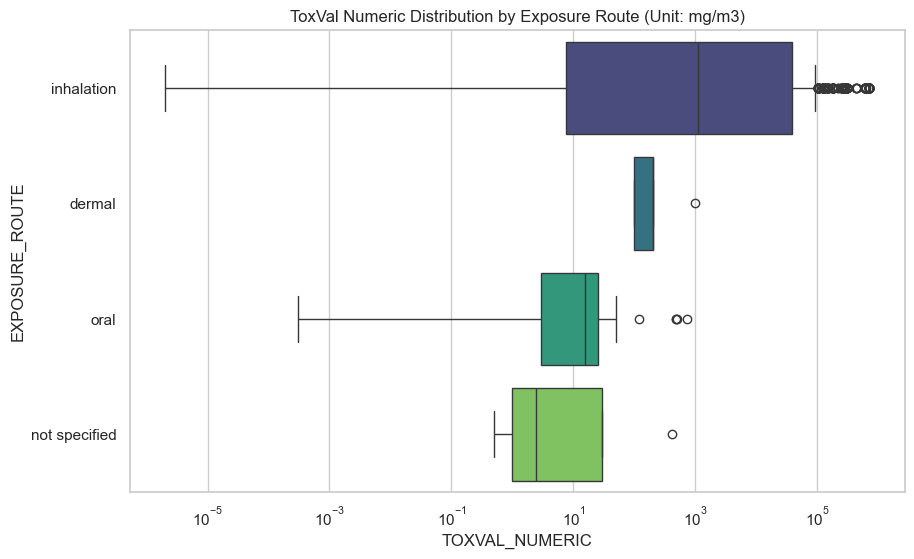

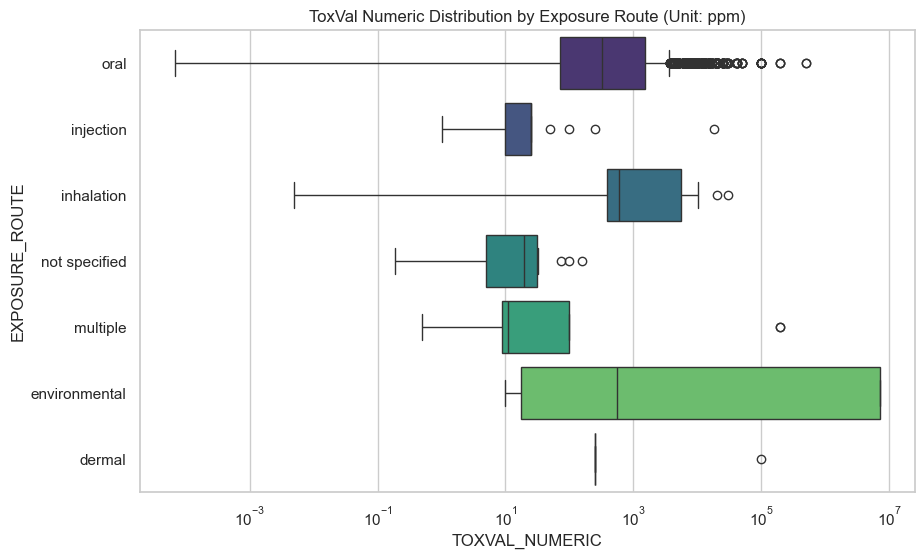

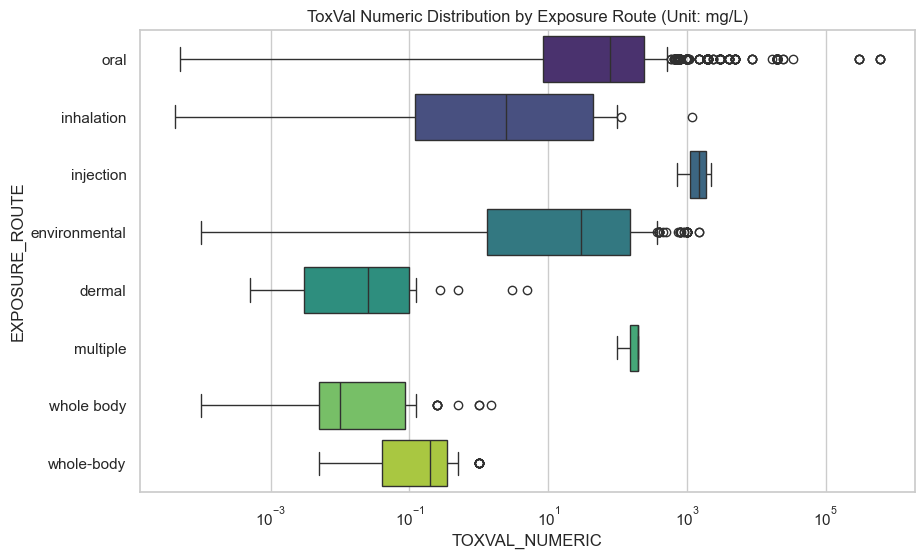

In [23]:
# Filter for top 5 units from updated df
if 'TOXVAL_UNITS' in df.columns and 'TOXVAL_NUMERIC' in df.columns:
    top_units = df['TOXVAL_UNITS'].value_counts().nlargest(5).index

    for unit in top_units:
        unit_df = df[df['TOXVAL_UNITS'] == unit]
        if 'EXPOSURE_ROUTE' in unit_df.columns and unit_df['EXPOSURE_ROUTE'].nunique() > 1:
            plt.figure(figsize=(10, 6))
            sns.boxplot(data=unit_df, x='TOXVAL_NUMERIC', y='EXPOSURE_ROUTE', palette="viridis")
            plt.xscale('log')
            plt.title(f"ToxVal Numeric Distribution by Exposure Route (Unit: {unit})")
            plt.show()

## 7. Verify there are plants species:


In [24]:
# 1. Contar filas por Super Categoría (Plantas y Flores)
# Ajustado a SPECIES_SUPERCATEGORY
plants_mask = df['SPECIES_SUPERCATEGORY'] == "Flowers, Trees, Shrubs, Ferns"
plants_count = plants_mask.sum()

# 2. Contar filas por Nombre Común específico
birds_foot_mask = df['SPECIES_COMMON'] == "Bird's-foot Trefoils"
birds_foot_count = birds_foot_mask.sum()

print(f"Registros en la categoría 'Flowers, Trees, Shrubs, Ferns': {plants_count}")
print(f"Registros con nombre común 'Bird's-foot Trefoils': {birds_foot_count}")

# Opcional: ver una muestra de esos registros
if plants_count > 0:
    print("\nMuestra de plantas detectadas:")
    display(df[plants_mask][['NAME', 'SPECIES_COMMON', 'SPECIES_SUPERCATEGORY']].head(5))


Registros en la categoría 'Flowers, Trees, Shrubs, Ferns': 13
Registros con nombre común 'Bird's-foot Trefoils': 13

Muestra de plantas detectadas:


,NAME,SPECIES_COMMON,SPECIES_SUPERCATEGORY
93799,Decoquinate,Bird's-foot Trefoils,"Flowers, Trees, Shrubs, Ferns"
94421,Tolclofos-methyl,Bird's-foot Trefoils,"Flowers, Trees, Shrubs, Ferns"
94765,Acequinocyl,Bird's-foot Trefoils,"Flowers, Trees, Shrubs, Ferns"
94836,Epoxiconazole,Bird's-foot Trefoils,"Flowers, Trees, Shrubs, Ferns"
94868,"(2R,6S)-Fenpropimorph",Bird's-foot Trefoils,"Flowers, Trees, Shrubs, Ferns"


In [25]:
# List ALL unique species as requested
print("\n--- ALL Unique Species in Dataset ---")
if 'SPECIES_COMMON' in df.columns:
    all_species = sorted(df['SPECIES_COMMON'].dropna().unique())
    print(f"Total unique species: {len(all_species)}")
    for s in all_species:
        print(f"- {s}")
else:
    print("SPECIES_COMMON column not found.")


--- ALL Unique Species in Dataset ---
Total unique species: 31
- American Mink
- Bird's-foot Trefoils
- Cat
- Chicken
- Cow Family
- Dog
- Eel Order
- European Rabbit
- Gerbil
- Guinea Pig
- Guinea Pig, Rat
- Hamster
- House Mouse
- Human
- Japanese Quail
- Mink
- Monkey
- Mouse
- Mouse, Rat
- Northern Bobwhite Quail
- Pig
- Primate
- Quail
- Rabbit
- Rat
- Rhesus Macaque
- Sheep
- Western European House Mouse
- Zebra Danio
- cat, guinea pig
- rodent


## 8. ToxVal Numeric: Physical and Biological Consistency

This analysis identifies potentially erroneous `TOXVAL_NUMERIC` values by checking physical limits (e.g., concentrations > 100%) and biological plausibility (e.g., doses > 100,000 mg/kg).

The "reasonableness" of a value depends on:
- **TOXVAL_UNITS**: Mass vs Concentration.
- **EXPOSURE_ROUTE**: Oral vs Inhalation.
- **TOXVAL_TYPE**: Lethal (LD50) vs No-Effect (NOAEL).

In [26]:
import pandas as pd
import numpy as np

# 1. Unified Normalization Factors for Mass/Concentration
mass_conv_sorted = [
    ('mg/kg-day', 1.0), ('mg/kg/day', 1.0), ('ug/kg-day', 0.001), ('ng/kg-day', 0.000001),
    ('mg/kg bw', 1.0), ('ug/kg bw', 0.001), ('ug/kg', 0.001), ('ng/kg', 0.000001),
    ('mg/kg', 1.0), ('g/kg', 1000.0), ('mg/g', 1000.0), ('ug/mg', 1.0)
]

def classify_toxval_unified(row):
    val = row['TOXVAL_NUMERIC']
    unit = str(row['TOXVAL_UNITS']).lower().strip()
    tox_type = str(row['TOXVAL_TYPE']).lower().strip()
    if pd.isnull(val): return None
    
    # --- EXCLUSIONS (Specialized Units/Types) ---
    # Skip Slope factors, Potency, Inverse metrics, and Inhalation mg/m3 (gases reach high levels)
    if '-1' in unit or '^-1' in unit or 'cancer' in tox_type or 'slope' in tox_type or 'mg/m3' in unit: 
        return None
    
    # --- PHYSICAL ERRORS (Absolutely Impossible) ---
    # Concentrations > 100% (or 1M ppm)
    if 'ppm' in unit and val > 1000000: return 'Error: Physical (> 100% conc)'
    pure_percent = ['%', '% v/v', '% diet', '% w/v', '% weight']
    if unit in pure_percent and val > 100: return 'Error: Physical (> 100% conc)'
    
    # Doses > 1,000,000 mg/kg (animal made of 100% poison)
    # 1. Check mg/kg equivalent
    multiplier = None
    for u_str, factor in mass_conv_sorted:
        if u_str in unit:
            multiplier = factor
            break
    if multiplier is not None:
        norm_val = val * multiplier
        if norm_val > 1000000: return 'Error: Physical (Dose > Animal Weight)'
        if norm_val > 100000: return 'Review: Suspicious (Dose > 100g/kg)'
        
    # --- BIOLOGICAL SUSPICION (Concentrations > 10%) ---
    # Includes mg/L (water) and ppm (diet) where 10% is extremely high for almost any hazard
    if ('mg/l' in unit or 'ppm' in unit) and val > 100000:
        return 'Review: Suspicious (Concentration > 10%)'
            
    return None

# Apply classification
df['TOXVAL_OUTLIER_FLAG'] = df.apply(classify_toxval_unified, axis=1)

outliers_found = df[df['TOXVAL_OUTLIER_FLAG'].notnull()]
print(f"Detected {len(outliers_found)} suspicious or erroneous ToxVal records.")
if not outliers_found.empty:
    # Show results sorted by magnitude for audit
    display(outliers_found.sort_values(by='TOXVAL_NUMERIC', ascending=False)[['NAME', 'TOXVAL_NUMERIC', 'TOXVAL_UNITS', 'TOXVAL_TYPE', 'EXPOSURE_ROUTE', 'TOXVAL_OUTLIER_FLAG', 'SOURCE']])
else:
    print("No outliers detected with the current refined filters.")

Detected 61 suspicious or erroneous ToxVal records.


,NAME,TOXVAL_NUMERIC,TOXVAL_UNITS,TOXVAL_TYPE,EXPOSURE_ROUTE,TOXVAL_OUTLIER_FLAG,SOURCE
71035,Ethanol,7100000.0,ppm,LOEL,environmental,Error: Physical (> 100% conc),ECOTOX
71034,Ethanol,7100000.0,ppm,LOEL,environmental,Error: Physical (> 100% conc),ECOTOX
71033,Ethanol,7100000.0,ppm,LOEL,environmental,Error: Physical (> 100% conc),ECOTOX
95519,Clethodim,1133000.0,mg/kg,LD50,oral,Error: Physical (Dose > Animal Weight),EFSA
66441,Magnesium silicate,800000.0,mg/kg-day,LOEL,injection,Review: Suspicious (Dose > 100g/kg),ECOTOX
...,...,...,...,...,...,...,...
88093,Carbendazim,164000.0,mg/kg-day,LOEL,injection,Review: Suspicious (Dose > 100g/kg),ECOTOX
114582,Egg white,101000.0,mg/kg,LD50,oral,Review: Suspicious (Dose > 100g/kg),TEST
114583,Egg white,101000.0,mg/kg,LD50,oral,Review: Suspicious (Dose > 100g/kg),TEST
114584,Egg white,101000.0,mg/kg,LD50,oral,Review: Suspicious (Dose > 100g/kg),TEST


## 9. Final Data Cleaning and Export

Identify and remove rows flagged as biological outliers, plant-related, or suspicious/erroneous based on the criteria in sections 5, 7, and 8. The final cleaned dataset is saved to a CSV file.

In [27]:
# Define masks based on criteria in sections 5, 7, and 8
bio_outliers_mask = (df['STUDY_DURATION_YEARS'] > df['SPECIES_COMMON'].map(lifespan_map))
plants_mask = (df['SPECIES_SUPERCATEGORY'] == "Flowers, Trees, Shrubs, Ferns")
suspicious_mask = df['TOXVAL_OUTLIER_FLAG'].notnull()

# Keep only 'experimental' records
non_experimental_mask = (df['EXPERIMENTAL_RECORD'] != "experimental")

# Eliminate rows with 'Human'
human_mask = df['SPECIES_COMMON'].str.contains("Human", na=False)

# Eliminate specific species: Sheep, Rhesus Macaque, Mink, Gerbil
to_eliminate = ["Sheep", "Rhesus Macaque", "Mink", "Gerbil"]
eliminate_mask = df['SPECIES_COMMON'].isin(to_eliminate)

# 3. Combine all exclusion criteria
to_remove_mask = bio_outliers_mask | plants_mask | suspicious_mask | non_experimental_mask | human_mask | eliminate_mask

print(f"Rows to remove: {to_remove_mask.sum()}")
print(f" - Biological outliers: {bio_outliers_mask.sum()}")
print(f" - Plant records: {plants_mask.sum()}")
print(f" - Suspicious/Error records: {suspicious_mask.sum()}")
print(f" - Non-experimental records: {non_experimental_mask.sum()}")
print(f" - Human records: {human_mask.sum()}")
print(f" - Other eliminated species: {eliminate_mask.sum()}")

# 4. Drop flagged rows and remove redundant column
df_cleaned = df[~to_remove_mask].copy()
df_cleaned = df_cleaned.drop(columns=['EXPERIMENTAL_RECORD'])

# 5. Species name transformations
species_map = {
    "Western European House Mouse": "Mouse",
    "House Mouse": "Mouse",
    "Mouse, Rat": "Rat",
    "Guinea Pig, Rat": "Rat"
}
df_cleaned['SPECIES_COMMON'] = df_cleaned['SPECIES_COMMON'].replace(species_map)

# 6. Save final cleaned dataset to CSV
output_csv = '../02_processed_data/ToxValDB_v9.7.0_Cleaned_01.tsv'
df_cleaned.to_csv(output_csv, index=False)
print(f"\nCleaned dataset saved to: {output_csv}")
print(f"Final dataset shape: {df_cleaned.shape}")

Rows to remove: 9906
 - Biological outliers: 5
 - Plant records: 13
 - Suspicious/Error records: 61
 - Non-experimental records: 9649
 - Human records: 3410
 - Other eliminated species: 30

Cleaned dataset saved to: ../02_processed_data/ToxValDB_v9.7.0_Cleaned_01.tsv
Final dataset shape: (106153, 35)
